<a href="https://colab.research.google.com/github/victor836768/piv_chess/blob/main/notebooks/etapa2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
from google.colab import drive
import csv
import os
import json
import pandas as pd
from PIL import Image, ImageOps
from collections import defaultdict
import matplotlib.pyplot as plt

#ens connectem al drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive/')

drive_path = '/content/drive/MyDrive/PIV PROJECT V2'
data_zip = f'{drive_path}/data/raw/Dataset.v2i.coco.zip'
models_dir = f'{drive_path}/models'
resultats_dir = f'{drive_path}/resultats'
local_data_dir = '/content/local_data'

if not os.path.exists('/content/local_data'):
    print("Descomprimint dataset...")
    !unzip -oq "{data_zip}" -d "{local_data_dir}"
    print("Dataset descomprimit correctament!")
else:
    print("El dataset ja estava descomprimit a /content/local_data. Saltant aquest pas.")

versio_manifest = "v1"
manifest_dir = f'{drive_path}/resultats/particions_manifest_{versio_manifest}.csv'
df_manifest = pd.read_csv(manifest_dir)

# Baixem el codi del repo dins de la màquina virtual de Colab
!git clone https://github.com/victor836768/piv_chess
%cd piv_chess

VERSIO = "v1"
html_out_path= os.path.join(resultats_dir, f"resum_classificador_informe_{VERSIO}.html")
linies_informe = []
imatges_informe = []

def registrar(text=""):
    text_str = str(text)
    print(text_str)
    linies_informe.append(text_str)

# Mostrar les primeres 5 files i el recompte per partició
registrar(df_manifest.head())
registrar("\nRecompte per partició:")
registrar(df_manifest["split"].value_counts())

# Convertir a diccionari {file_name: split} per fer-lo servir al codi:
file_to_split = dict(zip(df_manifest["file_name"], df_manifest["split"]))


El dataset ja estava descomprimit a /content/local_data. Saltant aquest pas.
Cloning into 'piv_chess'...
remote: Enumerating objects: 63, done.
remote: Counting objects: 100% (63/63), done.
remote: Compressing objects: 100% (54/54), done.
remote: Total 63 (delta 12), reused 6 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (63/63), 2.80 MiB | 8.59 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/piv_chess/piv_chess
                                           file_name group  split
0  G072_IMG089_jpg.rf.790412fc30620b4cd7711d406dd...  G072    val
1  G061_IMG098_jpg.rf.dda45cb89591a09cd1e0d580545...  G061  train
2  G028_IMG089_jpg.rf.dc3dc223b5ef066efffaebd7741...  G028    val
3  G091_IMG045_jpg.rf.01a539e5c55e5dad07634eef429...  G091  train
4  G019_IMG044_jpg.rf.ba1187d9c220145ee5ba9bfa109...  G019  train

Recompte per partició:
split
train    1470
val       311
test      296
Name: count, dtype: int64


In [9]:
def pad_to_square(img, fill_color=(114, 114, 114)):
    w, h = img.size
    max_side = max(w, h)
    pad_left = (max_side - w) // 2
    pad_top = (max_side - h) // 2
    pad_right = max_side - w - pad_left
    pad_bottom = max_side - h - pad_top
    return ImageOps.expand(img, (pad_left, pad_top, pad_right, pad_bottom), fill=fill_color)



 Paquet de retalls trobat a /content/drive/MyDrive/PIV PROJECT V2/data/processed/retalls_96x96.zip. Descomprimint...

Retalls preparats! Total: 43142 peces
   - Train: 30840 | Val: 6527 | Test: 5775


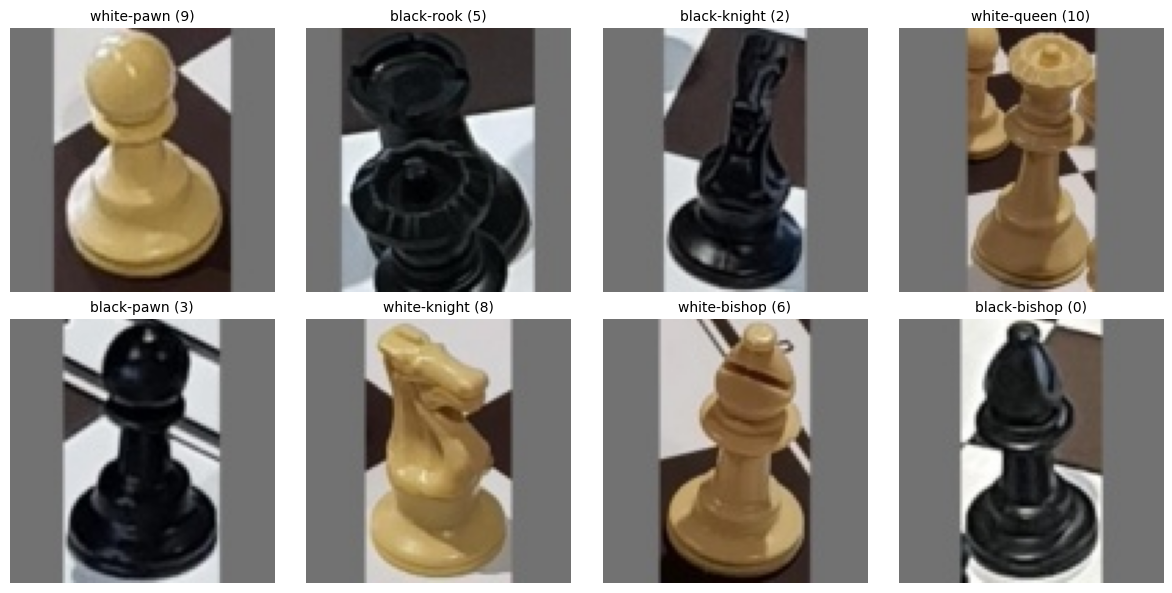

In [10]:
#1. preparem rutes
json_dir = f'{local_data_dir}/train/_annotations.coco.json'
imatges_dir = f'{local_data_dir}/train/'

retalls_dir = "/content/local_data/local_retalls/"
manifest_retalls_local = os.path.join(retalls_dir, "retalls_manifest.csv")

if not os.path.exists(retalls_dir):
    os.makedirs(retalls_dir, exist_ok=True)

processed_dir = f"{drive_path}/data/processed"

TARGET_SIZE = (96, 96)
zip_retalls_drive = (
    f"{processed_dir}/retalls_{TARGET_SIZE[0]}x{TARGET_SIZE[1]}.zip"
)

#llegirem el json, on ens diu la classe dels retalls
with open(json_dir, "r", encoding="utf-8") as f:
  coco = json.load(f)

active_cats = [cat for cat in coco["categories"] if cat["id"] != 0]
sorted_cats = sorted(active_cats, key=lambda x: x["id"])
cat_id_to_idx = {cat["id"]: idx for idx, cat in enumerate(sorted_cats)}
idx_to_label = {idx: cat["name"] for idx, cat in enumerate(sorted_cats)}

#3. farem un for per cada anotacio del manifest de la db original per a fer el retall i el noou manifest del retall i crearem el zip si no existeix.

if os.path.exists(zip_retalls_drive):
  print(
      f"\n Paquet de retalls trobat a {zip_retalls_drive}. Descomprimint..."
  )
  os.makedirs(retalls_dir, exist_ok=True)
  !unzip -oq "{zip_retalls_drive}" -d /
  df_retalls = pd.read_csv(manifest_retalls_local)
else:
  print("\n Generant retalls per primera vegada (pot trigar uns segons)...")
  os.makedirs(retalls_dir, exist_ok=True)

  images_info = {img["id"]: img for img in coco["images"]}
  manifest_retalls = []

  # Agrupem anotacions per foto per obrir cada imatge una sola vegada
  anotacions_per_foto = defaultdict(list)
  for ann in coco["annotations"]:
    if ann["category_id"] in cat_id_to_idx:
      anotacions_per_foto[ann["image_id"]].append(ann)

  # Recorrem cada foto un sol cop
  for image_id, llista_anns in anotacions_per_foto.items():
    img_info = images_info[image_id]
    fname = img_info["file_name"]
    img_path = os.path.join(imatges_dir, fname)

    if not os.path.exists(img_path) or fname not in file_to_split:
      continue

    with Image.open(img_path) as img:
      img = img.convert("RGB")
      for ann in llista_anns:
        x, y, w, h = map(int, ann["bbox"])
        if w <= 2 or h <= 2:
          continue

        # RETALLAR -> PADDING -> RESIZE
        crop = img.crop((
            max(0, x),
            max(0, y),
            min(img.width, x + w),
            min(img.height, y + h),
        ))
        crop_sq = pad_to_square(crop)
        crop_resized = crop_sq.resize(TARGET_SIZE, Image.Resampling.BILINEAR)

        crop_save_path = os.path.join(retalls_dir, f"crop_{ann['id']}.jpg")
        crop_resized.save(crop_save_path, quality=95)

        manifest_retalls.append({
            "crop_path": crop_save_path,
            "label_idx": cat_id_to_idx[ann["category_id"]],
            "label_name": idx_to_label[cat_id_to_idx[ann["category_id"]]],
            "split": file_to_split[fname],
        })

  # Guardem el manifest local i empaquetem cap al Drive
  df_crops = pd.DataFrame(manifest_retalls)
  df_crops.to_csv(manifest_retalls_local, index=False)

  print(f" Comprimint retalls cap al Drive: {zip_retalls_drive}")
  !zip -rq "{zip_retalls_drive}" "{retalls_dir}"

df_train = df_retalls[df_crops["split"] == "train"].reset_index(drop=True)
df_val = df_retalls[df_crops["split"] == "val"].reset_index(drop=True)
df_test = df_retalls[df_crops["split"] == "test"].reset_index(drop=True)

registrar(f"\nRetalls preparats! Total: {len(df_crops)} peces")
registrar(
    f"   - Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}"
)

#ensenyarem uns 8 retalls ja preparats per entrar a la cnn
mostra = df_train.sample(8)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, (_, fila) in zip(axes.flat, mostra.iterrows()):
  img = Image.open(fila['crop_path'])
  ax.imshow(img)
  ax.set_title(f"{fila['label_name']} ({fila['label_idx']})", fontsize=10)
  ax.axis('off')

plt.tight_layout()
plt.show()


In [20]:
import torch
import torch.nn as nn
import copy
import time
import random
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader

seed = 123
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print("Treballant amb:", device)

hparams = {
    'batch_size': 64,
    'num_epochs': 5,
    'test_batch_size': 64,
    'num_classes': 12,
    'img_size': 96,
    'learning_rate_cnn': 1e-3,
    'log_interval': 50,
}

image_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class ChessPiecesDataset(Dataset):

    def __init__(self, df_subset, retalls_dir_dir, transform=None):
        self.df = df_subset.reset_index(drop=True)
        self.retalls_dir = retalls_dir_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        nom_fitxer = os.path.basename(self.df.loc[idx, 'crop_path'])
        ruta_img = os.path.join(self.retalls_dir, nom_fitxer)

        label = int(self.df.loc[idx, 'label_idx'])
        img = Image.open(ruta_img).convert('RGB')

        if self.transform:
            img = self.transform(img)

        return img, label

      # Filtrem per la columna split
train_df = df_retalls[df_retalls['split'] == 'train'].reset_index(drop=True)
val_df   = df_retalls[df_retalls['split'] == 'val']
test_df  = df_retalls[df_retalls['split'] == 'test']

# classe ChessPiecesDataset
chess_trainset = ChessPiecesDataset(train_df, retalls_dir, transform=image_transform)
chess_valset   = ChessPiecesDataset(val_df,   retalls_dir, transform=image_transform)
chess_testset  = ChessPiecesDataset(test_df,  retalls_dir, transform=image_transform)

# DataLoaders
train_loader = DataLoader(chess_trainset, batch_size=hparams['batch_size'], shuffle=True, drop_last=False)
val_loader   = DataLoader(chess_valset,   batch_size=hparams['test_batch_size'], shuffle=False, drop_last=False)
test_loader  = DataLoader(chess_testset,  batch_size=hparams['test_batch_size'], shuffle=False, drop_last=False)

print(f"Training: {len(chess_trainset)}, Validation: {len(chess_valset)}, Test: {len(chess_testset)}")

Treballant amb: cuda
Training: 30840, Validation: 6527, Test: 5775


In [21]:
class ConvBlock(nn.Module):
    def __init__(
        self,
        num_inp_channels: int,
        num_out_fmaps: int,
        kernel_size: int = 3,
        pool_size: int = 2
    ) -> None:
        super().__init__()
        self.conv = nn.Conv2d(
            in_channels=num_inp_channels,
            out_channels=num_out_fmaps,
            kernel_size=kernel_size,
            padding=1
        )
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=pool_size, stride=pool_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.maxpool(self.relu(self.conv(x)))


class ChessCNN(nn.Module):
    def __init__(self, num_classes: int = 12) -> None:
        super().__init__()

        self.conv1 = ConvBlock(num_inp_channels=3,  num_out_fmaps=32)
        self.conv2 = ConvBlock(num_inp_channels=32, num_out_fmaps=64)
        self.conv3 = ConvBlock(num_inp_channels=64, num_out_fmaps=128)
        self.conv4 = ConvBlock(num_inp_channels=128, num_out_fmaps=256)


        self.mlp = nn.Sequential(
            nn.Linear(256 * 6 * 6, 256),
            nn.ReLU(inplace=True),
            nn.Linear(256, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)

        bsz, nch, height, width = x.shape
        x = x.reshape(bsz, -1)
        y = self.mlp(x)
        return y


In [22]:
from typing import Tuple

def get_nn_nparams(net: torch.nn.Module) -> int:
    return sum([torch.numel(p) for p in list(net.parameters())])

def compute_accuracy(predicted_batch: torch.Tensor, label_batch: torch.Tensor) -> int:
    pred = predicted_batch.argmax(dim=1, keepdim=True)
    acum = pred.eq(label_batch.view_as(pred)).sum().item()
    return acum

def train_epoch_cnn(
    train_loader: torch.utils.data.DataLoader,
    network: torch.nn.Module,
    optimizer: torch.optim.Optimizer,
    criterion: torch.nn.Module,
    log_interval: int,
) -> Tuple[float, float]:
    network.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = network(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        batch_size = target.size(0)
        total_loss += loss.item() * batch_size
        total_correct += compute_accuracy(output, target)
        total_samples += batch_size

        if batch_idx % log_interval == 0:
            print(f'Batch {batch_idx}: training loss {loss.item():.4f}')

    return total_loss / total_samples, 100.0 * total_correct / total_samples

@torch.no_grad()
def evaluate(data_loader, network, criterion):
    network.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for data, target in data_loader:
        data, target = data.to(device), target.to(device)
        output = network(data)
        loss = criterion(output, target)

        batch_size = target.size(0)
        total_loss += loss.item() * batch_size
        total_correct += compute_accuracy(output, target)
        total_samples += batch_size

    return total_loss / total_samples, 100.0 * total_correct / total_samples

Paràmetres totals de la CNN: 2751052
Batch 0: training loss 2.4703
Batch 50: training loss 1.0423
Batch 100: training loss 0.4995
Batch 150: training loss 0.5228
Batch 200: training loss 0.2930
Batch 250: training loss 0.1485
Batch 300: training loss 0.1483
Batch 350: training loss 0.0425
Batch 400: training loss 0.1124
Batch 450: training loss 0.1648
Epoch 1/5: train loss 0.4247 (acc 86.12%) | val loss 0.0580 (acc 98.05%)
Batch 0: training loss 0.0097
Batch 50: training loss 0.0354
Batch 100: training loss 0.0111
Batch 150: training loss 0.0565
Batch 200: training loss 0.1013
Batch 250: training loss 0.0681
Batch 300: training loss 0.0533
Batch 350: training loss 0.0826
Batch 400: training loss 0.0278
Batch 450: training loss 0.0270
Epoch 2/5: train loss 0.0565 (acc 98.30%) | val loss 0.0348 (acc 98.96%)
Batch 0: training loss 0.0391
Batch 50: training loss 0.0053
Batch 100: training loss 0.0152
Batch 150: training loss 0.0186
Batch 200: training loss 0.0147
Batch 250: training loss 0

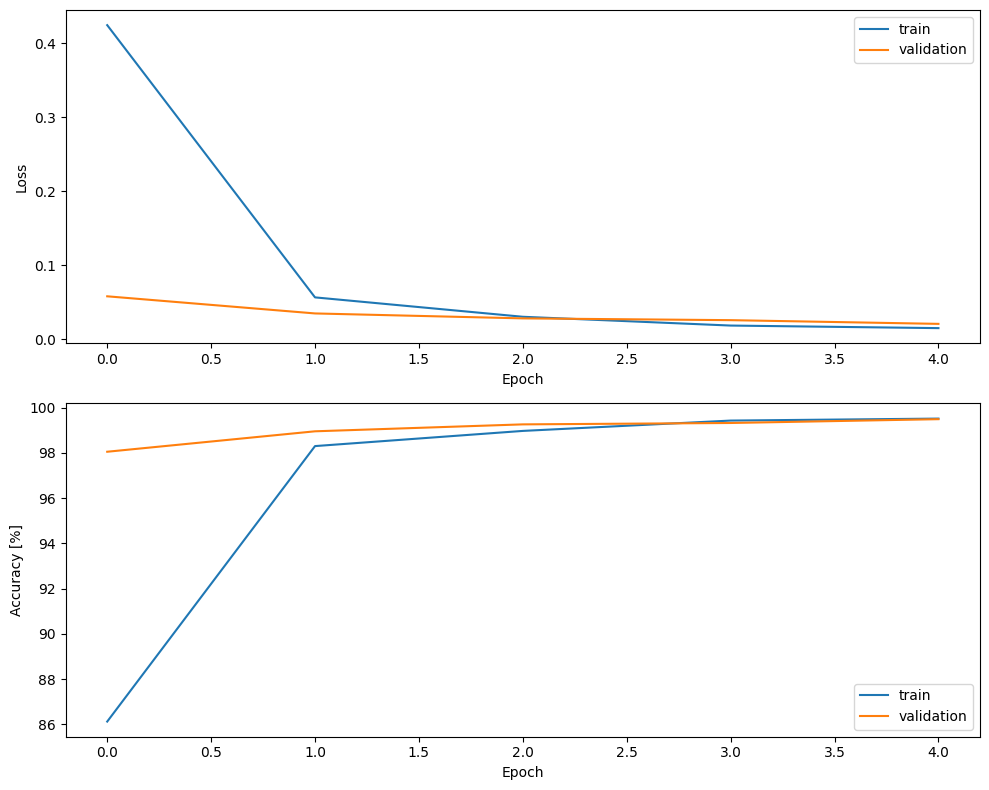

Model guardat correctament al Drive!


In [25]:
import os

network = ChessCNN(num_classes=hparams['num_classes']).to(device)
print(f"Paràmetres totals de la CNN: {get_nn_nparams(network)}")

optimizer = torch.optim.Adam(network.parameters(), lr=hparams['learning_rate_cnn'])
criterion = nn.CrossEntropyLoss()

train_losses_cnn, val_losses_cnn = [], []
train_accs_cnn, val_accs_cnn = [], []


for epoch in range(hparams['num_epochs']):
    train_loss, train_acc = train_epoch_cnn(train_loader, network, optimizer, criterion, hparams['log_interval'])
    val_loss, val_acc = evaluate(val_loader, network, criterion)

    train_losses_cnn.append(train_loss)
    train_accs_cnn.append(train_acc)
    val_losses_cnn.append(val_loss)
    val_accs_cnn.append(val_acc)

    print(f"Epoch {epoch + 1}/{hparams['num_epochs']}: "
          f"train loss {train_loss:.4f} (acc {train_acc:.2f}%) | "
          f"val loss {val_loss:.4f} (acc {val_acc:.2f}%)")


final_cnn = copy.deepcopy(network)


plt.figure(figsize=(10, 8))
plt.subplot(2, 1, 1)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.plot(train_losses_cnn, label='train')
plt.plot(val_losses_cnn, label='validation')
plt.legend()

plt.subplot(2, 1, 2)
plt.xlabel('Epoch')
plt.ylabel('Accuracy [%]')
plt.plot(train_accs_cnn, label='train')
plt.plot(val_accs_cnn, label='validation')
plt.legend()
plt.tight_layout()
plt.show()


models_dir = '/content/drive/MyDrive/Projecte_Escacs/models'
os.makedirs(models_dir, exist_ok=True)
torch.save(final_cnn.state_dict(), f'{models_dir}/cnn_baseline_v1.pt')
print("Model guardat correctament al Drive!")

In [12]:
with open(html_out_path, "w", encoding="utf-8") as f:
  f.write(
      "<html><head><meta charset='utf-8'></head><body"
      " style='font-family:sans-serif; padding:20px;'>\n"
  )
  f.write(
      "<pre style='background:#f4f4f4; padding:15px; border-radius:8px;"
      " font-size:14px;'>\n"
  )
  f.write("\n".join(linies_informe))
  f.write("\n</pre>\n<hr>\n")
  f.write("\n".join(imatges_informe))
  f.write("\n</body></html>")

print(f"✅ HTML desat correctament amb {len(imatges_informe)} imatges a: {html_out_path}")

✅ HTML desat correctament amb 0 imatges a: /content/drive/MyDrive/PIV PROJECT V2/resultats/resum_classificador_informe_v1.html
